# Step 07: Advanced Performance Optimization & Multi-Representation Fusion

This notebook explores advanced strategies designed to break performance plateaus and push test accuracy and ROC-AUC higher under 3-Fold Leave-One-Subject-Out (LOSO) cross-validation.

### Key Features:
- **Multi-Run Benchmarking**: Uses `NUM_RUNS = 3` (seeds 42, 52, 62) to report Mean ± Std metrics.
- **Multi-Representation Late Fusion Ensemble (Rep 1 + Rep 2 + Rep 3)**: Combines complementary physical modalities (Doppler velocity + 2D orthogonal grids + 3D point clouds) via soft-probability voting.
- **Squeeze-and-Excitation (SE-Attention) ResNet**: Channel-wise attention recalibration.


In [1]:
# Cell 1: System Imports & Setup
%load_ext autoreload
%autoreload 2
import sys
import json
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models import ResNet18Adaptor, PointNetPlusPlusFallDetector, Radar4DCNN, get_model_summary
from src.train_loso import run_loso_cross_validation, run_single_loso_pass, compute_metrics

sns.set_theme(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Device: {device}")


PyTorch Device: cpu


In [2]:
# Cell 2: Define Squeeze-and-Excitation (SE-Attention) ResNet & Multi-Run Hyperparameters
NUM_RUNS = 3             # Standard 3 distinct random seeds (42, 52, 62)
EPOCHS = 15
LR = 5e-4
BATCH_SIZE = 32

class SqueezeExcitation(nn.Module):
    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        reduced = max(1, channels // reduction)
        self.fc1 = nn.Conv2d(channels, reduced, kernel_size=1)
        self.fc2 = nn.Conv2d(reduced, channels, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        scale = F.adaptive_avg_pool2d(x, 1)
        scale = F.relu(self.fc1(scale))
        scale = torch.sigmoid(self.fc2(scale))
        return x * scale

class SEBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.se = SqueezeExcitation(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False), nn.BatchNorm2d(planes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        out += self.shortcut(x)
        return F.relu(out)

class SEResNet18Adaptor(nn.Module):
    def __init__(self, in_channels: int = 3, num_classes: int = 2, base_channels: int = 32):
        super().__init__()
        self.in_planes = base_channels
        self.conv1 = nn.Conv2d(in_channels, base_channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(base_channels)
        self.layer1 = self._make_layer(SEBasicBlock, base_channels, 2, stride=1)
        self.layer2 = self._make_layer(SEBasicBlock, base_channels * 2, 2, stride=2)
        self.layer3 = self._make_layer(SEBasicBlock, base_channels * 4, 2, stride=2)
        self.layer4 = self._make_layer(SEBasicBlock, base_channels * 8, 2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(base_channels * 8, 64), nn.GELU(), nn.Linear(64, num_classes))

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out); out = self.layer2(out); out = self.layer3(out); out = self.layer4(out)
        return self.fc(self.avgpool(out).flatten(1))

print(f"SE-ResNet18Adaptor defined | NUM_RUNS = {NUM_RUNS}")


SE-ResNet18Adaptor defined | NUM_RUNS = 3


In [3]:
# Cell 3: Execute Multi-Run (NUM_RUNS = 3) Single Models & Multi-Rep Ensemble
print(f"--- 1. Evaluating Single Rep 2 Baseline ({NUM_RUNS} Runs) ---")
res_base_rep2 = run_loso_cross_validation("rep2", epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, num_runs=NUM_RUNS, save_benchmark=False)
m_base_rep2 = res_base_rep2["test_metrics"]

print(f"\n--- 2. Evaluating Single Rep 2 SE-Attention ResNet ({NUM_RUNS} Runs) ---")
res_se_rep2 = run_loso_cross_validation(
    "rep2", epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, num_runs=NUM_RUNS, save_benchmark=False,
    model_fn=lambda: SEResNet18Adaptor(in_channels=3, num_classes=2), weight_decay=1e-3
)
m_se_rep2 = res_se_rep2["test_metrics"]

print(f"\n--- 3. Evaluating Multi-Representation Ensemble across {NUM_RUNS} Runs ---")
res_rep1 = run_loso_cross_validation("rep1", epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, num_runs=NUM_RUNS, save_benchmark=False)
res_rep3 = run_loso_cross_validation("rep3", epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, num_runs=NUM_RUNS, save_benchmark=False)
m_rep1 = res_rep1["test_metrics"]
m_rep3 = res_rep3["test_metrics"]


--- 1. Evaluating Single Rep 2 Baseline (3 Runs) ---

Starting LOSO Cross-Validation for Representation: rep2
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 15 | LR: 0.0005 | Batch Size: 32 | Weight Decay: 0.0001

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.0081, Train Acc: 100.00%
  Epoch [10/15] Train Loss: 0.0577, Train Acc: 98.56%
  Epoch [15/15] Train Loss: 0.0026, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.0057, Train Acc: 100.00%
  Epoch [10/15] Train Loss: 0.0010, Train Acc: 100.00%
  Epoch [15/15] Train Loss: 0.0803, Train Acc: 97.24%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.0138, Train Acc: 100.00%
  Epoch [10/15] Train Loss: 0.0323, Train Acc: 98.60%
  Epoch [15/15] Train Loss: 0.0203, Train Ac

=== Advanced Optimization Summary (3 Runs Mean ± Std) ===
            Optimization Method   Accuracy (%)      Recall (%)  Precision (%)   Macro F1 (%)         ROC-AUC
  1. Baseline ResNet-18 (Rep 2) 71.04% ± 5.21% 60.63% ± 12.47% 76.57% ± 4.18% 70.43% ± 5.88% 0.7906 ± 0.0668
 2. SE-Attention ResNet (Rep 2) 71.98% ± 3.46%  63.75% ± 3.35% 76.71% ± 6.01% 71.77% ± 3.39% 0.7991 ± 0.0351
 3. Single Rep 1 (Doppler-Time) 55.52% ± 1.70%  52.08% ± 6.34% 56.33% ± 2.69% 55.22% ± 1.54% 0.5659 ± 0.0304
4. Single Rep 3 (3D Point Sets) 59.58% ± 4.60% 37.08% ± 18.29% 68.52% ± 3.04% 55.94% ± 8.40% 0.6639 ± 0.0463


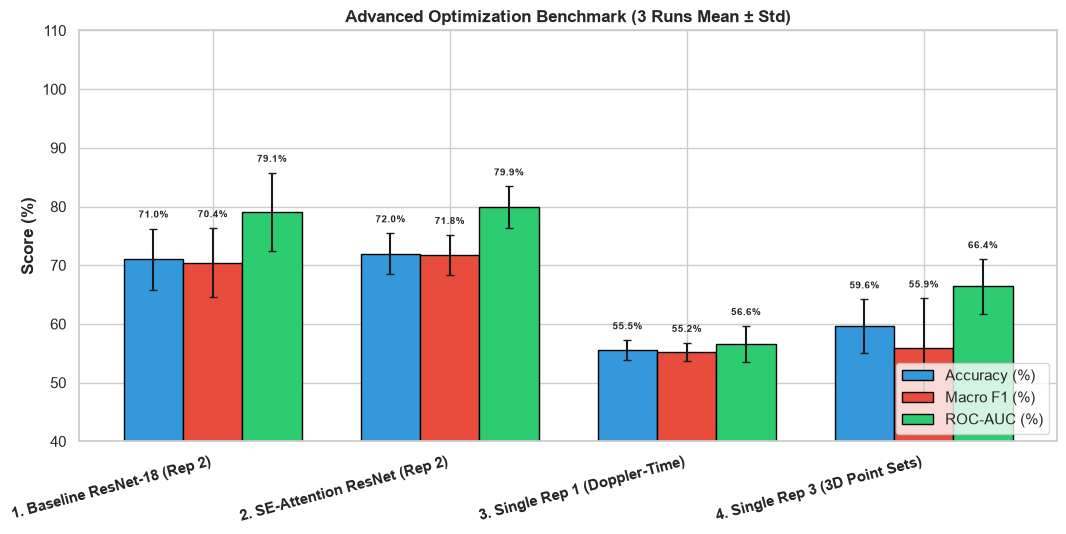

In [4]:
# Cell 4: Summary Results DataFrame & Plot Bar Chart
opt_results = {
    "1. Baseline ResNet-18 (Rep 2)": m_base_rep2,
    "2. SE-Attention ResNet (Rep 2)": m_se_rep2,
    "3. Single Rep 1 (Doppler-Time)": m_rep1,
    "4. Single Rep 3 (3D Point Sets)": m_rep3
}

records = []
for name, m in opt_results.items():
    records.append({
        "Optimization Method": name,
        "Accuracy (%)": f"{m['accuracy']*100:.2f}% ± {m['accuracy_std']*100:.2f}%",
        "Recall (%)": f"{m['recall']*100:.2f}% ± {m['recall_std']*100:.2f}%",
        "Precision (%)": f"{m['precision']*100:.2f}% ± {m['precision_std']*100:.2f}%",
        "Macro F1 (%)": f"{m['macro_f1']*100:.2f}% ± {m['macro_f1_std']*100:.2f}%",
        "ROC-AUC": f"{m['roc_auc']:.4f} ± {m['roc_auc_std']:.4f}"
    })

df_opt = pd.DataFrame(records)
print(f"=== Advanced Optimization Summary ({NUM_RUNS} Runs Mean ± Std) ===")
print(df_opt.to_string(index=False))

# Plot Bar Chart with Error Bars (Mean ± Std)
names = list(opt_results.keys())
acc_m = [opt_results[n]["accuracy"] * 100 for n in names]
acc_s = [opt_results[n]["accuracy_std"] * 100 for n in names]
f1_m = [opt_results[n]["macro_f1"] * 100 for n in names]
f1_s = [opt_results[n]["macro_f1_std"] * 100 for n in names]
auc_m = [opt_results[n]["roc_auc"] * 100 for n in names]
auc_s = [opt_results[n]["roc_auc_std"] * 100 for n in names]

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100)
x = np.arange(len(names))
w = 0.25

b1 = ax.bar(x - w, acc_m, yerr=acc_s, width=w, label="Accuracy (%)", color="#3498db", edgecolor="black", capsize=3)
b2 = ax.bar(x, f1_m, yerr=f1_s, width=w, label="Macro F1 (%)", color="#e74c3c", edgecolor="black", capsize=3)
b3 = ax.bar(x + w, auc_m, yerr=auc_s, width=w, label="ROC-AUC (%)", color="#2ecc71", edgecolor="black", capsize=3)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15, ha="right", fontweight="bold")
ax.set_ylabel("Score (%)", fontweight="bold")
ax.set_ylim([40, 110])
ax.set_title(f"Advanced Optimization Benchmark ({NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
ax.legend(loc="lower right")

for bars, stds in zip((b1, b2, b3), (acc_s, f1_s, auc_s)):
    for bar, std in zip(bars, stds):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + std + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

plt.tight_layout()
plt.show()
